## 1.  packages

In [ ]:
!pip install -q transformers datasets sentencepiece sacremoses sacrebleu accelerate pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 867.8/867.8 kB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.0/129.0 kB 15.6 MB/s eta 0:00:00


## 2. settings & switch between T4 vs A100

In [ ]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import torch

MODEL_NAME = "facebook/nllb-200-distilled-600M"
DATA_DIR   = "data"
RAW_DIR    = "data/raw"
CKPT_DIR   = "ckpt/multi_no_helpers"   # google drive to survive disconnects
OUT_DIR    = "outputs"
for d in [DATA_DIR, RAW_DIR, CKPT_DIR, OUT_DIR]:
    os.makedirs(d, exist_ok=True)

CODES = {"az": "azj_Latn", "be": "bel_Cyrl", "en": "eng_Latn"}
DIRECTIONS = ["az-en", "en-az", "be-en", "en-be"]

assert torch.cuda.is_available(), "No GPU found - switch runtime to GPU"
gpu = torch.cuda.get_device_name(0)
# bf16 only on A100 H100 class GPUs (compute capability 8 +) T4 is 7.5 with fp16.
BF16 = torch.cuda.get_device_capability(0)[0] >= 8
print("GPU:", gpu, "| real bf16:", BF16, "| using:", "bf16" if BF16 else "fp16")

# same effective batch size (32) on both GPUs so results are comparable
if BF16:  # A100 / H100
    BATCH, ACCUM, GRAD_CKPT = 16, 2, False
else:     # T4
    BATCH, ACCUM, GRAD_CKPT = 4, 8, True

SEED = 42
LR = 5e-5
MAX_EPOCHS = 10
PATIENCE = 2
MAX_LEN = 128

GPU: Tesla T4 | real bf16: False | using: fp16


## 3. data TED corpus



In [ ]:
import glob, tarfile
from huggingface_hub import hf_hub_download, list_repo_files

REPO = "davidstap/ted_talks"
try:
    tar_path = hf_hub_download(repo_id=REPO, filename="data/TED.tar",
                               repo_type="dataset", local_dir=RAW_DIR)
except Exception as e:
    print("Download failed:", e)
    print("Files in repo:", list_repo_files(REPO, repo_type="dataset"))
    raise

TED_DIR = f"{RAW_DIR}/TED"
if not glob.glob(f"{TED_DIR}/**/ted.train.en", recursive=True):
    with tarfile.open(tar_path) as t:
        t.extractall(TED_DIR, filter="data")

print(sorted(glob.glob(f"{TED_DIR}/**/ted.*.az", recursive=True)))

data/TED.tar: reconstructing file:   0%|          |  0.00B /  706MB            

data/TED.tar: downloading bytes:           |  0.00B            

['data/raw/TED/test/ted.test.az', 'data/raw/TED/train/ted.train.az', 'data/raw/TED/validation/ted.dev.az']


## 4. sanity check on counts

In [ ]:
def read_lang(split, lang):
    path = glob.glob(f"{TED_DIR}/**/ted.{split}.{lang}", recursive=True)[0]
    with open(path, encoding="utf-8") as f:
        return f.read().split("\n")

raw = {s: {l: read_lang(s, l) for l in CODES} for s in ["train", "dev", "test"]}

for s in raw:
    lens = {l: len(v) for l, v in raw[s].items()}
    assert len(set(lens.values())) == 1, f"{s}: files not aligned {lens}"
    for low in ["az", "be"]:
        n = sum(1 for x, e in zip(raw[s][low], raw[s]["en"]) if x.strip() and e.strip())
        print(f"{s:5s} {low}-en: {n}")

print([x for x in raw["train"]["az"] if x.strip()][:3])
print([e for e in raw["train"]["en"] if e.strip()][:3])

train az-en: 5946
train be-en: 4509
dev   az-en: 671
dev   be-en: 248
test  az-en: 903
test  be-en: 664
['Zəhmət olmasa, sizə xitab edən sözlər eşidəndə əlinizi qaldırın.', 'Razılaşdıq? Hə?', 'Onda başlayaq.']
["Amongst all the troubling deficits we struggle with today — we think of financial and economic primarily — the ones that concern me most is the deficit of political dialogue — our ability to address modern conflicts as they are, to go to the source of what they're all about and to understand the key players and to deal with them.", 'We who are diplomats, we are trained to deal with conflicts between states and issues between states.', 'And I can tell you, our agenda is full.']


## 5. building 4 directions az-en, en-az, be-en, en-be


In [ ]:
import json

def build(split):
    rows = []
    for low in ["az", "be"]:
        for x, e in zip(raw[split][low], raw[split]["en"]):
            x, e = x.strip(), e.strip()
            if not (x and e):
                continue
            rows.append({"src": x, "tgt": e, "src_lang": CODES[low],
                         "tgt_lang": CODES["en"], "direction": f"{low}-en"})
            rows.append({"src": e, "tgt": x, "src_lang": CODES["en"],
                         "tgt_lang": CODES[low], "direction": f"en-{low}"})
    with open(f"{DATA_DIR}/{split}.jsonl", "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    return rows

data = {s: build(s) for s in ["train", "dev", "test"]}
print({s: len(r) for s, r in data.items()})

{'train': 20910, 'dev': 1838, 'test': 3134}


## 6. tokenizer & translation function

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import sacrebleu

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
AMP_DTYPE = torch.bfloat16 if BF16 else torch.float16

def translate_and_score(model, tok, rows, out_dir, batch=32, beams=5):
    os.makedirs(out_dir, exist_ok=True)
    model.eval()
    scores = {}
    for d in DIRECTIONS:
        sub = [r for r in rows if r["direction"] == d]
        tok.src_lang = sub[0]["src_lang"]
        bos = tok.convert_tokens_to_ids(sub[0]["tgt_lang"])
        hyps = []
        for i in range(0, len(sub), batch):
            enc = tok([r["src"] for r in sub[i:i+batch]], return_tensors="pt",
                      padding=True, truncation=True, max_length=MAX_LEN).to(model.device)
            with torch.no_grad(), torch.autocast("cuda", dtype=AMP_DTYPE):
                gen = model.generate(**enc, forced_bos_token_id=bos, num_beams=beams,
                                     max_new_tokens=MAX_LEN, max_length=None)
            hyps += tok.batch_decode(gen, skip_special_tokens=True)
        refs = [r["tgt"] for r in sub]
        with open(f"{out_dir}/{d}.hyp", "w", encoding="utf-8") as f: f.write("\n".join(hyps) + "\n")
        with open(f"{out_dir}/{d}.ref", "w", encoding="utf-8") as f: f.write("\n".join(refs) + "\n")
        scores[d] = {"BLEU": round(sacrebleu.corpus_bleu(hyps, [refs]).score, 2),
                     "chrF": round(sacrebleu.corpus_chrf(hyps, [refs]).score, 2)}
        print(d, scores[d])
    return scores

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/3.55k [00:00<?, ?B/s]

## 7. off the shelf NLLB baseline ( ie no training)



In [ ]:
QUICK= False # True for a fast pipeline check (100 sentences per direction) otherwise keeps full

base = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).cuda()
test_rows = data["test"]
if QUICK:
    test_rows = [r for d in DIRECTIONS for r in [x for x in data["test"] if x["direction"] == d][:100]]

base_dir = f"{OUT_DIR}/nllb_offtheshelf" + ("_quick" if QUICK else "")
base_scores = translate_and_score(base, tok, test_rows, base_dir)
with open(f"{base_dir}/scores.json", "w") as f:
    json.dump(base_scores, f, indent=2)
del base; torch.cuda.empty_cache()

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.46GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

az-en {'BLEU': 21.62, 'chrF': 45.26}
en-az {'BLEU': 11.68, 'chrF': 41.47}
be-en {'BLEU': 32.67, 'chrF': 55.36}
en-be {'BLEU': 22.4, 'chrF': 50.05}


## 8. tokenizing for the training

In [ ]:
from datasets import load_dataset

ds = load_dataset("json", data_files={"train": f"{DATA_DIR}/train.jsonl",
                                      "dev":   f"{DATA_DIR}/dev.jsonl"})

def encode(ex):
    tok.src_lang, tok.tgt_lang = ex["src_lang"], ex["tgt_lang"]
    return tok(ex["src"], text_target=ex["tgt"], max_length=MAX_LEN, truncation=True)

ds = ds.map(encode, remove_columns=ds["train"].column_names)  # no num_proc: tok is changed per example
print(ds)

Generating train split: 0 examples [00:00, ? examples/s]

Generating dev split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/20910 [00:00<?, ? examples/s]

Map:   0%|          | 0/1838 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 20910
    })
    dev: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1838
    })
})


## 9. sanity check on language tags
all correct: az-en  azj_Latn / eng_Latn, en-az eng_Latn / azj_Latn, en-be  eng_Latn / bel_Cyrl

In [ ]:
for i in [0, 1, len(data["train"]) - 1]:
    print("direction:", data["train"][i]["direction"])
    print("  input :", tok.convert_ids_to_tokens(ds["train"][i]["input_ids"])[:3], "...")
    print("  labels:", tok.convert_ids_to_tokens(ds["train"][i]["labels"])[:3], "...")

direction: az-en
  input : ['azj_Latn', '▁Z', 'əh'] ...
  labels: ['eng_Latn', '▁Please', '▁raise'] ...
direction: en-az
  input : ['eng_Latn', '▁Please', '▁raise'] ...
  labels: ['azj_Latn', '▁Z', 'əh'] ...
direction: en-be
  input : ['eng_Latn', '▁(', 'App'] ...
  labels: ['bel_Cyrl', '▁(', 'В'] ...


## 10. training
after a disconnect  RESUME=True needs checkpoints still on disk

In [ ]:
import math, inspect, transformers
from transformers import (DataCollatorForSeq2Seq, Seq2SeqTrainer,
                          Seq2SeqTrainingArguments, EarlyStoppingCallback)
print("transformers", transformers.__version__)

RESUME = False

model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
if GRAD_CKPT:
    model.gradient_checkpointing_enable()

steps_per_epoch = math.ceil(len(ds["train"]) / (BATCH * ACCUM))
WARMUP_STEPS = int(0.05 * steps_per_epoch * MAX_EPOCHS)
print("steps per epoch:", steps_per_epoch, "| warmup steps:", WARMUP_STEPS)

settings = dict(
    output_dir=CKPT_DIR,
    learning_rate=LR, per_device_train_batch_size=BATCH,
    per_device_eval_batch_size=BATCH, gradient_accumulation_steps=ACCUM,
    num_train_epochs=MAX_EPOCHS, warmup_steps=WARMUP_STEPS, weight_decay=0.01,
    eval_strategy="epoch", save_strategy="epoch", save_total_limit=2,
    load_best_model_at_end=True, metric_for_best_model="eval_loss",
    bf16=BF16, fp16=not BF16, seed=SEED, logging_steps=50, report_to="none",
    group_by_length=True,
)

allowed = set(inspect.signature(Seq2SeqTrainingArguments.__init__).parameters)
if "group_by_length" not in allowed:
    print("group_by_length not available in this version - skipping it")
    settings.pop("group_by_length")
unknown = [k for k in settings if k not in allowed]
assert not unknown, f"Not accepted by this version: {unknown} - send this to Claude"

args = Seq2SeqTrainingArguments(**settings)
trainer = Seq2SeqTrainer(
    model=model, args=args, train_dataset=ds["train"], eval_dataset=ds["dev"],
    data_collator=DataCollatorForSeq2Seq(tok, model=model),
    callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
)

trainer.train(resume_from_checkpoint=True if RESUME else None)
trainer.save_model(f"{CKPT_DIR}/best")
tok.save_pretrained(f"{CKPT_DIR}/best")
print("best checkpoint:", trainer.state.best_model_checkpoint, "| best dev loss:", trainer.state.best_metric)

transformers 5.16.1


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

steps per epoch: 654 | warmup steps: 327
group_by_length not available in this version - skipping it


Epoch,Training Loss,Validation Loss
1,12.980057,1.516202
2,12.092560,1.515727
3,11.042350,1.530954
4,9.824664,1.554008


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

best checkpoint: ckpt/multi_no_helpers/checkpoint-1308 | best dev loss: 1.515726923942566


In [ ]:
m = trainer.model
print("best checkpoint:", trainer.state.best_model_checkpoint)
print("best dev loss  :", trainer.state.best_metric)

# q1: are the shared weights linked?
shared = m.model.shared.weight
for name, w in [("encoder embed", m.model.encoder.embed_tokens.weight),
                ("decoder embed", m.model.decoder.embed_tokens.weight),
                ("lm_head      ", m.lm_head.weight)]:
    print(name, "| same memory:", w.data_ptr() == shared.data_ptr(),
          "| same values:", torch.equal(w.detach().cpu(), shared.detach().cpu()))

# q2: does the loaded model give the best dev loss again?
print("dev loss now   :", trainer.evaluate()["eval_loss"])

best checkpoint: ckpt/multi_no_helpers/checkpoint-1308
best dev loss  : 1.515726923942566
encoder embed | same memory: True | same values: True
decoder embed | same memory: True | same values: True
lm_head       | same memory: True | same values: True


Training Loss,Validation Loss,Epoch
9.824664,1.515727,4


dev loss now   : 1.515726923942566


## 11. translating test set with model


In [ ]:
best = AutoModelForSeq2SeqLM.from_pretrained(f"{CKPT_DIR}/best").cuda()
print("same values as shared:", torch.equal(best.lm_head.weight, best.model.shared.weight))
my_scores = translate_and_score(best, tok, data["test"], f"{OUT_DIR}/multi_no_helpers")
del best; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/509 [00:00<?, ?it/s]

same values as shared: True
az-en {'BLEU': 23.06, 'chrF': 45.88}
en-az {'BLEU': 11.98, 'chrF': 41.89}
be-en {'BLEU': 34.66, 'chrF': 56.39}
en-be {'BLEU': 22.58, 'chrF': 49.2}


## 12. settings are saved

In [ ]:
run_info = {
    "model": MODEL_NAME,
    "transformers_version": transformers.__version__,
    "gpu": gpu,
    "precision": "bf16" if BF16 else "fp16",
    "seed": SEED, "lr": LR,
    "batch": BATCH, "grad_accum": ACCUM, "effective_batch": BATCH * ACCUM,
    "warmup_steps": WARMUP_STEPS, "weight_decay": 0.01,
    "group_by_length": settings.get("group_by_length", False),
    "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "max_len": MAX_LEN,
    "epochs_trained": trainer.state.epoch,
    "best_checkpoint": trainer.state.best_model_checkpoint,
    "best_dev_loss": trainer.state.best_metric,
    "beams": 5,
    "data_source": "davidstap/ted_talks (Hugging Face)",
    "test_scores": my_scores,
}
with open(f"{OUT_DIR}/multi_no_helpers/run_info.json", "w") as f:
    json.dump(run_info, f, indent=2)
run_info

{'model': 'facebook/nllb-200-distilled-600M',
 'transformers_version': '5.16.1',
 'gpu': 'Tesla T4',
 'precision': 'fp16',
 'seed': 42,
 'lr': 5e-05,
 'batch': 4,
 'grad_accum': 8,
 'effective_batch': 32,
 'warmup_steps': 327,
 'weight_decay': 0.01,
 'group_by_length': False,
 'max_epochs': 10,
 'patience': 2,
 'max_len': 128,
 'epochs_trained': 4.0,
 'best_checkpoint': 'ckpt/multi_no_helpers/checkpoint-1308',
 'best_dev_loss': 1.515726923942566,
 'beams': 5,
 'data_source': 'davidstap/ted_talks (Hugging Face)',
 'test_scores': {'az-en': {'BLEU': 23.06, 'chrF': 45.88},
  'en-az': {'BLEU': 11.98, 'chrF': 41.89},
  'be-en': {'BLEU': 34.66, 'chrF': 56.39},
  'en-be': {'BLEU': 22.58, 'chrF': 49.2}}}

## 13. downloading outputs

In [ ]:
import shutil
shutil.make_archive("outputs", "zip", OUT_DIR)
try:
    from google.colab import files
    files.download("outputs.zip")
except ImportError:
    print("not on colab outputs.zip is in the notebook folder")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. training loss was accumulated, this is checked & handled below

In [ ]:
sample = ds["train"].shuffle(seed=0).select(range(1000))
print("real loss on training data:", trainer.evaluate(eval_dataset=sample)["eval_loss"])

Training Loss,Validation Loss,Epoch
9.824664,1.207028,4


real loss on training data: 1.2070280313491821


In [ ]:
import gc, math

for name in ["trainer", "model", "best", "base"]:
    if name in globals():
        del globals()[name]
gc.collect(); torch.cuda.empty_cache()

def probe(accum, steps):
    m = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
    if GRAD_CKPT:
        m.gradient_checkpointing_enable()
    a = Seq2SeqTrainingArguments(
        output_dir="probe", learning_rate=0.0, warmup_steps=0,
        per_device_train_batch_size=4, gradient_accumulation_steps=accum,
        max_steps=steps, logging_steps=1, save_strategy="no", eval_strategy="no",
        bf16=BF16, fp16=not BF16, seed=SEED, report_to="none",
    )
    t = Seq2SeqTrainer(model=m, args=a, train_dataset=ds["train"],
                       data_collator=DataCollatorForSeq2Seq(tok, model=m))
    t.train()
    logs = [l for l in t.state.log_history if "loss" in l]
    loss = sum(l["loss"] for l in logs) / len(logs)
    norms = [l["grad_norm"] for l in logs if "grad_norm" in l and math.isfinite(l["grad_norm"])]
    gnorm = sum(norms) / len(norms) if norms else float("nan")
    del t, m; gc.collect(); torch.cuda.empty_cache()
    return loss, gnorm

loss_a, gn_a = probe(accum=1, steps=40)
loss_b, gn_b = probe(accum=8, steps=5)
print(f"Run A (accum 1): loss {loss_a:.3f} | grad_norm {gn_a:.3f}")
print(f"Run B (accum 8): loss {loss_b:.3f} | grad_norm {gn_b:.3f}")
print(f"loss ratio B/A: {loss_b/loss_a:.2f} | grad_norm ratio B/A: {gn_b/gn_a:.2f}")

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Step,Training Loss
1,1.768838
2,2.003560
3,1.573559
4,1.487054
5,1.609612
6,1.902298
7,1.905191
8,1.332484
9,1.663408
10,2.306541


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Step,Training Loss
1,13.582596
2,14.910697
3,15.863399
4,18.012705
5,15.884762


Run A (accum 1): loss 1.956 | grad_norm 3.860
Run B (accum 8): loss 15.651 | grad_norm 13.324
loss ratio B/A: 8.00 | grad_norm ratio B/A: 3.45


In [ ]:
import gc, glob, json
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments, DataCollatorForSeq2Seq

train_sample = ds["train"].shuffle(seed=0).select(range(1000))

def measure(path):
    m = AutoModelForSeq2SeqLM.from_pretrained(path)
    a = Seq2SeqTrainingArguments(output_dir="eval_tmp", per_device_eval_batch_size=BATCH,
                                 bf16=BF16, fp16=not BF16, report_to="none")
    t = Seq2SeqTrainer(model=m, args=a, data_collator=DataCollatorForSeq2Seq(tok, model=m))
    out = {"train": t.evaluate(eval_dataset=train_sample)["eval_loss"],
           "dev":   t.evaluate(eval_dataset=ds["dev"])["eval_loss"]}
    del t, m; gc.collect(); torch.cuda.empty_cache()
    return out

ckpts = sorted(glob.glob(f"{CKPT_DIR}/checkpoint-*"), key=lambda p: int(p.split("-")[-1]))
print("checkpoints on disk:", ckpts)

measured = {0: measure(MODEL_NAME)}
for p in ckpts:
    epoch = round(int(p.split("-")[-1]) / steps_per_epoch) if "steps_per_epoch" in globals() else round(int(p.split("-")[-1]) / 654)
    measured[epoch] = measure(p)

for e, v in measured.items():
    print(f"epoch {e}: train loss {v['train']:.4f} | dev loss {v['dev']:.4f}")

with open(f"{OUT_DIR}/multi_no_helpers/measured_losses.json", "w") as f:
    json.dump(measured, f, indent=2)

checkpoints on disk: ['ckpt/multi_no_helpers/checkpoint-1308', 'ckpt/multi_no_helpers/checkpoint-2616']


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Training Loss,Validation Loss,Step
No log,1.893206,0


Training Loss,Validation Loss,Step
No log,1.937231,0


Loading weights:   0%|          | 0/509 [00:00<?, ?it/s]

...

Training Loss,Validation Loss,Step
No log,1.515727,0


Loading weights:   0%|          | 0/509 [00:00<?, ?it/s]

Training Loss,Validation Loss,Step
No log,0.989492,0


Training Loss,Validation Loss,Step
No log,1.554008,0


epoch 0: train loss 1.8932 | dev loss 1.9372
epoch 2: train loss 1.2070 | dev loss 1.5157
epoch 4: train loss 0.9895 | dev loss 1.5540


## 15. results

### plots, tables

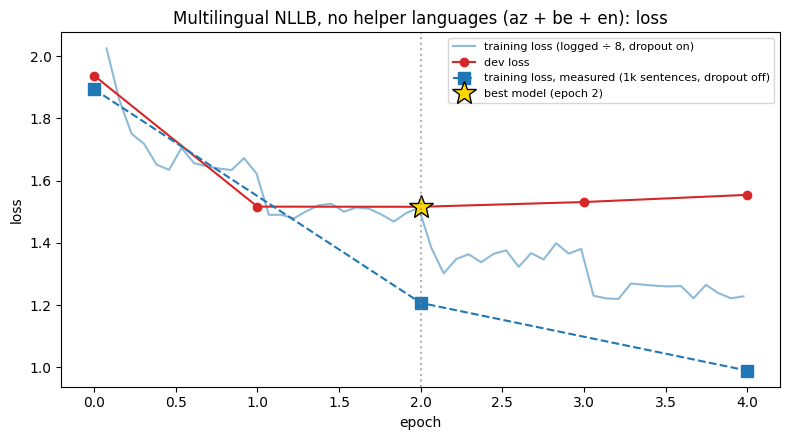

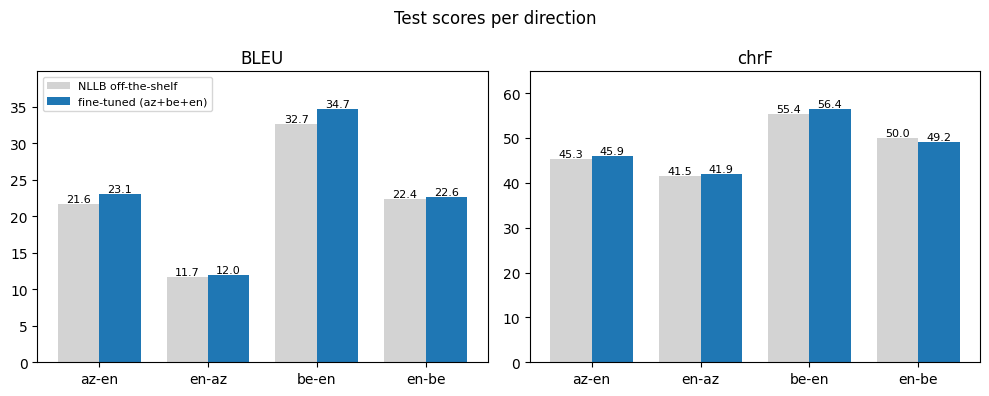

direction  BLEU base  BLEU ft      Δ | chrF base  chrF ft      Δ
az-en          21.62    23.06  +1.44 |     45.26    45.88  +0.62
en-az          11.68    11.98  +0.30 |     41.47    41.89  +0.42
be-en          32.67    34.66  +1.99 |     55.36    56.39  +1.03
en-be          22.40    22.58  +0.18 |     50.05    49.20  -0.85


In [ ]:
import os, glob, json
import matplotlib.pyplot as plt

TEST2_CONFIRMED = True
scale = ACCUM if TEST2_CONFIRMED else 1
res_dir = f"{OUT_DIR}/multi_no_helpers"

hist_file = f"{res_dir}/log_history.json"
if os.path.exists(hist_file):
    history = json.load(open(hist_file))
else:
    ckpts = sorted(glob.glob(f"{CKPT_DIR}/checkpoint-*"), key=lambda p: int(p.split("-")[-1]))
    history = json.load(open(f"{ckpts[-1]}/trainer_state.json"))["log_history"]
    json.dump(history, open(hist_file, "w"), indent=2)

measured = {int(k): v for k, v in json.load(open(f"{res_dir}/measured_losses.json")).items()}
base_s = json.load(open(f"{OUT_DIR}/nllb_offtheshelf/scores.json"))
mine_s = json.load(open(f"{res_dir}/run_info.json"))["test_scores"]

train = [(h["epoch"], h["loss"] / scale) for h in history if "loss" in h]
dev = {}
for h in history:
    if "eval_loss" in h and round(h["epoch"], 6) == round(h["epoch"]) and round(h["epoch"]) not in dev:
        dev[round(h["epoch"])] = h["eval_loss"]
dev = sorted(dev.items())
best_e, best_l = min(dev, key=lambda x: x[1])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot([e for e, _ in train], [l for _, l in train], color="tab:blue", alpha=0.5,
        label=f"training loss (logged ÷ {scale}, dropout on)")
ax.plot([0] + [e for e, _ in dev], [measured[0]["dev"]] + [l for _, l in dev],
        "o-", color="tab:red", label="dev loss")
me = sorted(measured)
ax.plot(me, [measured[e]["train"] for e in me], "s--", color="tab:blue", markersize=8,
        label="training loss, measured (1k sentences, dropout off)")
ax.plot(best_e, best_l, "*", color="gold", markersize=18, markeredgecolor="black",
        label=f"best model (epoch {best_e:.0f})")
ax.axvline(best_e, color="gray", linestyle=":", alpha=0.6)
ax.set_xlabel("epoch"); ax.set_ylabel("loss")
ax.set_title("Multilingual NLLB, no helper languages (az + be + en): loss")
ax.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.savefig(f"{res_dir}/loss_curves.png", dpi=200)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
x = range(len(DIRECTIONS)); w = 0.38
for ax, metric in zip(axes, ["BLEU", "chrF"]):
    b = [base_s[d][metric] for d in DIRECTIONS]
    m = [mine_s[d][metric] for d in DIRECTIONS]
    bars1 = ax.bar([i - w/2 for i in x], b, w, label="NLLB off-the-shelf", color="lightgray")
    bars2 = ax.bar([i + w/2 for i in x], m, w, label="fine-tuned (az+be+en)", color="tab:blue")
    ax.bar_label(bars1, fmt="%.1f", fontsize=8); ax.bar_label(bars2, fmt="%.1f", fontsize=8)
    ax.set_xticks(list(x)); ax.set_xticklabels(DIRECTIONS)
    ax.set_title(metric); ax.set_ylim(0, max(b + m) * 1.15)
axes[0].legend(loc="upper left", fontsize=8)
plt.suptitle("Test scores per direction")
plt.tight_layout()
plt.savefig(f"{res_dir}/scores_comparison.png", dpi=200)
plt.show()

print(f"{'direction':10s} {'BLEU base':>9s} {'BLEU ft':>8s} {'Δ':>6s} | {'chrF base':>9s} {'chrF ft':>8s} {'Δ':>6s}")
for d in DIRECTIONS:
    bb, mb = base_s[d]["BLEU"], mine_s[d]["BLEU"]
    bc, mc = base_s[d]["chrF"], mine_s[d]["chrF"]
    print(f"{d:10s} {bb:9.2f} {mb:8.2f} {mb-bb:+6.2f} | {bc:9.2f} {mc:8.2f} {mc-bc:+6.2f}")

In [ ]:
h = json.load(open(f"{OUT_DIR}/multi_no_helpers/log_history.json"))
g = [x["grad_norm"] for x in h if "grad_norm" in x]
real = [v / ACCUM for v in g]  # what the norm would have been if averaged
print(f"logged steps: {len(real)} | smallest real norm: {min(real):.2f} | steps where real norm < 1: {sum(r < 1 for r in real)}")

logged steps: 52 | smallest real norm: 0.97 | steps where real norm < 1: 1


###  paired bootstrap resampling test

In [ ]:
for d in DIRECTIONS:
    print("=====", d)
    !sacrebleu {OUT_DIR}/multi_no_helpers/{d}.ref -i {OUT_DIR}/nllb_offtheshelf/{d}.hyp {OUT_DIR}/multi_no_helpers/{d}.hyp -m bleu chrf --paired-bs -f text

===== az-en
sacreBLEU: Found 2 systems.
sacreBLEU: Pre-computing BLEU statistics for 'Baseline: outputs/nllb_offtheshelf/az-en.hyp'
sacreBLEU: Pre-computing CHRF statistics for 'Baseline: outputs/nllb_offtheshelf/az-en.hyp'
sacreBLEU: Computing BLEU for 'outputs/multi_no_helpers/az-en.hyp' and extracting sufficient statistics
sacreBLEU:  > Performing paired bootstrap resampling test (# resamples: 1000)
sacreBLEU: Computing chrF2 for 'outputs/multi_no_helpers/az-en.hyp' and extracting sufficient statistics
sacreBLEU:  > Performing paired bootstrap resampling test (# resamples: 1000)
╒══════════════════════════════════════════════╤═════════════════════╤══════════════════════╕
│                                       System │  BLEU (μ ± 95% CI)  │  chrF2 (μ ± 95% CI)  │
╞══════════════════════════════════════════════╪═════════════════════╪══════════════════════╡
│ Baseline: outputs/nllb_offtheshelf/az-en.hyp │  21.6 (21.6 ± 1.2)  │  45.3 (45.2 ± 1.0)   │
├──────────────────────────────────

In [ ]:
for name in ["nllb_offtheshelf", "multi_no_helpers"]:
    hyps = open(f"{OUT_DIR}/{name}/en-be.hyp", encoding="utf-8").read()
    print(f"{name:18s} | і: {hyps.count('і')} | ў: {hyps.count('ў')} | и (Russian): {hyps.count('и')} | ы: {hyps.count('ы')}")

nllb_offtheshelf   | і: 2537 | ў: 1022 | и (Russian): 3 | ы: 2508
multi_no_helpers   | і: 2587 | ў: 948 | и (Russian): 0 | ы: 2360


So the en→be chrF drop is not caused by Russian forms. That idea is ruled out.

A correction: in an earlier check I treated ы as a sign of Russian. That was wrong: ы is a normal letter in Belarusian too. Only и is a reliable Russian signal.

In [ ]:
import sacrebleu

ref = open(f"{OUT_DIR}/multi_no_helpers/en-be.ref", encoding="utf-8").read().splitlines()
print(f"{'system':18s} | {'chars':>7s} | {'words':>6s} | {'len/ref':>7s} | і/1k | ў/1k | ы/1k")
for name, path in [("reference", None), ("nllb_offtheshelf", "nllb_offtheshelf"), ("multi_no_helpers", "multi_no_helpers")]:
    lines = ref if path is None else open(f"{OUT_DIR}/{path}/en-be.hyp", encoding="utf-8").read().splitlines()
    text = "\n".join(lines)
    n = len(text)
    ratio = "" if path is None else f"{sacrebleu.corpus_bleu(lines, [ref]).sys_len / sacrebleu.corpus_bleu(lines, [ref]).ref_len:.3f}"
    print(f"{name:18s} | {n:7d} | {len(text.split()):6d} | {ratio:>7s} | "
          f"{1000*text.count('і')/n:.1f} | {1000*text.count('ў')/n:.1f} | {1000*text.count('ы')/n:.1f}")

system             |   chars |  words | len/ref | і/1k | ў/1k | ы/1k
reference          |   61603 |   9739 |         | 39.3 | 13.5 | 37.0
nllb_offtheshelf   |   65513 |  10377 |   1.076 | 38.7 | 15.6 | 38.3
multi_no_helpers   |   64172 |  10170 |   1.055 | 40.3 | 14.8 | 36.8


In [ ]:
from sacrebleu.metrics import CHRF

ref = open(f"{OUT_DIR}/multi_no_helpers/en-be.ref", encoding="utf-8").read().splitlines()
hyp_base = open(f"{OUT_DIR}/nllb_offtheshelf/en-be.hyp", encoding="utf-8").read().splitlines()
hyp_ft   = open(f"{OUT_DIR}/multi_no_helpers/en-be.hyp", encoding="utf-8").read().splitlines()

for beta, label in [(2, "chrF2 (recall x2, default)"), (1, "chrF1 (equal weight)"), (0.5, "chrF0.5 (precision x2)")]:
    m = CHRF(beta=beta)
    b, f = m.corpus_score(hyp_base, [ref]).score, m.corpus_score(hyp_ft, [ref]).score
    print(f"{label:28s} | off-the-shelf {b:.2f} | fine-tuned {f:.2f} | change {f-b:+.2f}")

chrF2 (recall x2, default)   | off-the-shelf 50.05 | fine-tuned 49.20 | change -0.85
chrF1 (equal weight)         | off-the-shelf 49.12 | fine-tuned 48.63 | change -0.49
chrF0.5 (precision x2)       | off-the-shelf 48.22 | fine-tuned 48.07 | change -0.14


In [ ]:
!sacrebleu {OUT_DIR}/multi_no_helpers/en-be.ref -i {OUT_DIR}/nllb_offtheshelf/en-be.hyp {OUT_DIR}/multi_no_helpers/en-be.hyp -m chrf --chrf-beta 1 --paired-bs -f text

sacreBLEU: Found 2 systems.
sacreBLEU: Pre-computing CHRF statistics for 'Baseline: outputs/nllb_offtheshelf/en-be.hyp'
sacreBLEU: Computing chrF1 for 'outputs/multi_no_helpers/en-be.hyp' and extracting sufficient statistics
sacreBLEU:  > Performing paired bootstrap resampling test (# resamples: 1000)
╒══════════════════════════════════════════════╤══════════════════════╕
│                                       System │  chrF1 (μ ± 95% CI)  │
╞══════════════════════════════════════════════╪══════════════════════╡
│ Baseline: outputs/nllb_offtheshelf/en-be.hyp │  49.1 (49.1 ± 1.2)   │
├──────────────────────────────────────────────┼──────────────────────┤
│           outputs/multi_no_helpers/en-be.hyp │  48.6 (48.6 ± 1.2)   │
│                                              │     (p = 0.0879)     │
╘══════════════════════════════════════════════╧══════════════════════╛

------------------------------------------------------------
Paired bootstrap resampling test with 1000 resampling trial

In [ ]:
!sacrebleu {OUT_DIR}/multi_no_helpers/en-be.ref -i {OUT_DIR}/nllb_offtheshelf/en-be.hyp {OUT_DIR}/multi_no_helpers/en-be.hyp -m chrf --chrf-beta 1 --paired-bs -f text > {OUT_DIR}/multi_no_helpers/significance_en-be_chrf1.txt 2>&1

In [ ]:
for d in DIRECTIONS:
    !sacrebleu {OUT_DIR}/multi_no_helpers/{d}.ref -i {OUT_DIR}/nllb_offtheshelf/{d}.hyp {OUT_DIR}/multi_no_helpers/{d}.hyp -m bleu chrf --paired-bs -f text > {OUT_DIR}/multi_no_helpers/significance_{d}.txt 2>&1

In [ ]:
import json, os

test = [json.loads(l) for l in open(f"{DATA_DIR}/test.jsonl", encoding="utf-8")]

for folder in ["nllb_offtheshelf", "multi_no_helpers"]:
    for d in DIRECTIONS:
        src = [r["src"] for r in test if r["direction"] == d]
        with open(f"{OUT_DIR}/{folder}/{d}.src", "w", encoding="utf-8") as f:
            f.write("\n".join(src) + "\n")

        n_src = len(src)
        n_hyp = len(open(f"{OUT_DIR}/{folder}/{d}.hyp", encoding="utf-8").read().splitlines())
        n_ref = len(open(f"{OUT_DIR}/{folder}/{d}.ref", encoding="utf-8").read().splitlines())
        print(f"{folder:18s} {d} | src {n_src} | hyp {n_hyp} | ref {n_ref} | {'OK' if n_src == n_hyp == n_ref else 'MISMATCH'}")

nllb_offtheshelf   az-en | src 903 | hyp 903 | ref 903 | OK
nllb_offtheshelf   en-az | src 903 | hyp 903 | ref 903 | OK
nllb_offtheshelf   be-en | src 664 | hyp 664 | ref 664 | OK
nllb_offtheshelf   en-be | src 664 | hyp 664 | ref 664 | OK
multi_no_helpers   az-en | src 903 | hyp 903 | ref 903 | OK
multi_no_helpers   en-az | src 903 | hyp 903 | ref 903 | OK
multi_no_helpers   be-en | src 664 | hyp 664 | ref 664 | OK
multi_no_helpers   en-be | src 664 | hyp 664 | ref 664 | OK
